---
title: "Hermite interpolation"
subtitle: "Lecture 9: Chapter 3: Polynomial interpolation"
code-fold: true
format:
  html: default
  pdf: default
---

{{< include ../extras/_lecture-header.html >}}

In [8]:
# | include: false

using Plots, LaTeXStrings, Polynomials, Printf

## Previously.....

- Barycentric formula: for $x \not\in X$, $I_Xf(x) = \sum_{j=0}^n \frac{\lambda_j f(x_j)}{x - x_j} \Big/ \sum_{j=0}^n \frac{\lambda_j}{x - x_j}$ where $\lambda_j = \prod_{k\not=j} (x_j - x_k)^{-1}$,
- Barycentric formula requires $O(n)$ operations per evaluation and is numerically stable for Chebyshev nodes (with weights $(-1)^j$, halved for $j = 0, n$),
- Divided differences: $f[x_0,\dots,x_n]$ is the leading coefficient of $I_Xf$; it doesn't depend on the ordering of the nodes and is linear in $f$,
- Recursion: $f[x_0,\dots,x_n] = \frac{f[x_1,\dots,x_n] - f[x_0,\dots,x_{n-1}]}{x_n - x_0}$ (@thm-divided-diffs-2),
- Newton form: $I_Xf = \sum_{k=0}^n f[x_0,\dots,x_k] \, \pi_k$ where $\pi_k(x) = (x-x_0)\cdots(x-x_{k-1})$ (@thm-Newton-form),
- The coefficients can be read off from the *divided difference table*; adding a new node only adds one new term.

::: {.box}

**Exercise.** @exr-l08-bary-weights

:::

## Hermite Interpolation

Now consider distinct nodes $z_0, \dots, z_k$ with multiplicities $m_0, \dots, m_k \geq 1$ and let $X = \{\{ x_0, \dots, x_n \}\}$ be the *multiset* in which each $z_j$ appears $m_j$ times (so that $n+1 = \sum_{j=0}^k m_j$).

Hermite: find $p$ such that, for $j = 0, \dots, k$,

$$
\begin{align}
    p(z_j) &= f(z_j),  \nonumber\\
    p'(z_j) &= f'(z_j),  \nonumber\\
    &\vdots \nonumber\\
    p^{(m_j-1)}(z_j) &= f^{(m_j-1)}(z_j).
\end{align}
$$

When $m_j = 1$ for all $j$, this is the Lagrange interpolation problem.

::: {#exr-Hermite-1}

[](../exercises/bank.html#bank-exr-Hermite-1)

Let $f(x) = e^x$ and $X = \{\{0, 0, 1\}\}$ (so that $z_0 = 0$ with $m_0 = 2$, $z_1 = 1$ with $m_1 = 1$, and $n = 2$). Find the Hermite interpolant $p \in \mathcal P_2$ of $f$ on $X$ by writing $p(x) = a_0 + a_1 x + a_2 x^2$ and solving for the coefficients. Compare $p$ with the Taylor polynomial of degree $1$ about $0$ and with the Lagrange interpolant of $f$ on $\{0, 1\}$.

::: {.exercise-solution style="display: none;"}

We look for $p(x) = a_0 + a_1 x + a_2 x^2 \in \mathcal P_2$ with
$$
\begin{align}
    p(0) &= f(0) = 1, \nonumber\\
    p'(0) &= f'(0) = 1, \nonumber\\
    p(1) &= f(1) = e. \nonumber
\end{align}
$$
Since $p'(x) = a_1 + 2a_2 x$, the first two conditions give $a_0 = 1$ and $a_1 = 1$. The third gives $1 + 1 + a_2 = e$, so $a_2 = e - 2$ and
$$
    p(x) = 1 + x + (e - 2) x^2.
$$

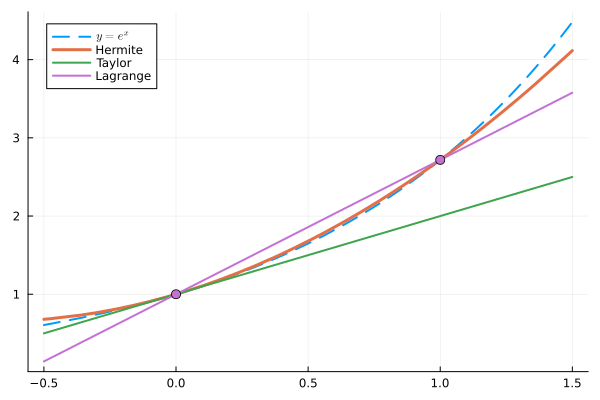

In [2]:
p_H(x) = 1 + x + (ℯ - 2)*x^2   # Hermite X = {{0, 0, 1}}
p_T(x) = 1 + x                 # Taylor (or Hermite on X = {{0,0}})
p_L(x) = 1 + (exp(1) - 1)*x    # Lagrange X ={0,1}

plot(exp, -0.5, 1.5; label=L"y = e^x", lw=2, linestyle=:dash)
plot!(p_H, -0.5, 1.5; label="Hermite", lw=3)
plot!(p_T, -0.5, 1.5; label="Taylor", lw=2)
plot!(p_L, -0.5, 1.5; label="Lagrange", lw=2)
scatter!([0, 1], [1, ℯ]; markersize=5, primary=false)

:::

:::

::: {#exr-Taylor-Hermite}

[](../exercises/bank.html#bank-exr-Taylor-Hermite)

What is the least degree polynomial interpolant on $X = \{\{x_0, x_0, \dots, x_0\}\}$ (where $x_0$ is repeated $n+1$ times)?

::: {.exercise-solution style="display: none;"}

The Taylor polynomial
$$
    T_f(x) = \sum_{j=0}^n \frac{f^{(j)}(x_0)}{j!} (x - x_0)^j \in \mathcal P_n
$$
satisfies $T_f^{(l)}(x_0) = f^{(l)}(x_0)$ for $l = 0, \dots, n$. So Hermite interpolation on a single node repeated $n+1$ times is Taylor expansion, and Lagrange interpolation (all $m_j = 1$) is the other extreme.

:::

:::

::: {#thm-Hermite}

There exists a unique polynomial of degree at most $n$ solving the Hermite interpolation problem.

:::

::: {.proof}
See @exr-l09-hermite-exist.
:::

Again, we define the divided differences (but now for the more general case where we may have repeated interpolation nodes):

::: {#def-divided-diffs-repeated}

We define the divided difference $f[x_{0}, \dots, x_n]$ to be the leading coefficient in the polynomial interpolation $p\in \mathcal P_n$ solving the Hermite interpolation problem for $f$ on $X$:

$$
\begin{align}
    p(x) = f[x_0,\dots,x_n] x^n + q(x)
\end{align}
$$

where $q \in \mathcal P_{n-1}$ and $p^{(l)}(z_j) = f^{(l)}(z_j)$ for $l = 0,\dots,m_j-1$ and $j = 0, \dots, k$.

:::
::: {#thm-divided-diffs-recursion}

Suppose that $f$ is sufficiently differentiable ($f \in C^{m-1}$ where $m := \max_j m_j$). Then, we have

$$
\begin{align}
    f[x_0, \dots, x_n] &= \begin{cases}
    \frac{f^{(n)}(x_0)}{n!} & \text{if } x_0 = x_1 = \dots = x_n \\
    \frac
        {f[x_1, \dots, x_n] - f[x_0, \dots, x_{n-1}]}
        {x_n - x_0} &\text{if } x_0 \not= x_n
    \end{cases}
\end{align}
$$

If the nodes are not all equal, we can always reorder $X$ so that $x_0 \not= x_n$ (the divided difference does not depend on the ordering of the nodes).

:::

::: {.proof name="non-examinable" collapse="true"}
You have seen above that the Taylor polynomial 

$$
\begin{align}
    T_f(x) =\sum_{j=0}^n \frac{f^{(j)}(x_0)}{j!}(x - x_0)^j 
\end{align}
$$

solves the Hermite interpolation problem on $X = \{\{x_0,\dots,x_n\}\}$ in the case where $x_0 = \dots = x_n$. For such $X$, the leading coefficient in this expression is $f[x_{0}, \dots, x_n] = \frac{f^{(n)}(x_0)}{n!}$. 

For the second case, suppose $x_0 \not= x_n$. We adapt the proof of @thm-divided-diffs-2.

*Ordering and linearity.* The Hermite interpolation problem only depends on the multiset $X$ and not on how we label its elements. Therefore $f[x_0,\dots,x_n]$ does not depend on the ordering of the nodes. Moreover, if $p$ and $q$ are the Hermite interpolants of $f$ and $g$ on $X$, then $p + cq \in \mathcal P_n$ satisfies the Hermite conditions for $f + cg$, and so $(f + cg)[x_0,\dots,x_n] = f[x_0,\dots,x_n] + c\, g[x_0,\dots,x_n]$.

*Multiplying by $(x - x_n)$.* Let $p \in \mathcal P_{n-1}$ be the Hermite interpolant of $f$ on $X' := \{\{x_0, \dots, x_{n-1}\}\}$ and define $g(x) := (x - x_n) f(x)$ and $q(x) := (x - x_n) p(x) \in \mathcal P_n$. We claim that $q$ is the Hermite interpolant of $g$ on $X$. Let $u := p - f$. By the product rule,
$$
    q^{(l)}(x) - g^{(l)}(x) = \frac{\mathrm d^l}{\mathrm dx^l} \big[ (x - x_n) u(x) \big] = (x - x_n) u^{(l)}(x) + l \, u^{(l-1)}(x)
$$
(drop the second term when $l = 0$). Let $z$ be a node which appears $m$ times in $X'$, so that $u^{(i)}(z) = 0$ for $i = 0, \dots, m-1$.

- If $z \not= x_n$, then $z$ also appears $m$ times in $X$. For $l \leq m - 1$, we have $u^{(l)}(z) = u^{(l-1)}(z) = 0$, and so $q^{(l)}(z) = g^{(l)}(z)$.
- If $z = x_n$, then $z$ appears $m + 1$ times in $X$ (with $m = 0$ if $x_n \not\in X'$). For $l \leq m$, the first term vanishes because $z - x_n = 0$, and the second term vanishes because $l - 1 \leq m - 1$ (or $l = 0$). Therefore $q^{(l)}(x_n) = g^{(l)}(x_n)$ for $l = 0, \dots, m$.

So $q$ satisfies all of the Hermite conditions for $g$ on $X$ and it is the Hermite interpolant of $g$ on $X$. Comparing leading coefficients, the coefficient of $x^n$ in $q$ is both $g[x_0, \dots, x_n]$ and the coefficient of $x^{n-1}$ in $p$, that is, $f[x_0,\dots,x_{n-1}]$. Therefore
$$
    \big( (x - x_n) f \big)[x_0, \dots, x_n] = f[x_0, \dots, x_{n-1}].
$$
Applying this to the reordered multiset $\{\{x_1, \dots, x_n, x_0\}\}$ gives $\big( (x - x_0) f \big)[x_0, \dots, x_n] = f[x_1, \dots, x_n]$.

Since $(x - x_0) f(x) - (x - x_n) f(x) = (x_n - x_0) f(x)$, linearity gives
$$
\begin{align}
    &(x_n - x_0) f[x_0,\dots,x_n] \nonumber\\
    &= \big( (x - x_0) f \big)[x_0, \dots, x_n] - \big( (x - x_n) f \big)[x_0, \dots, x_n] \nonumber\\ 
    &= f[x_1, \dots, x_n] - f[x_0, \dots, x_{n-1}].
\end{align}
$$
Dividing by $x_n - x_0 \not= 0$ gives the result.
:::

For distinct nodes, this is exactly the proof of @thm-divided-diffs-2 (where only the case $l = 0$ appears).

## Newton form and divided difference table with repeated nodes

The Newton form from @thm-Newton-form still holds when nodes are repeated. As before, let $\pi_0(x) = 1$ and $\pi_k(x) = (x - x_0)(x-x_1)\cdots(x - x_{k-1})$, where repeated nodes now give repeated factors (e.g. for $X = \{\{0,0,\pi,\pi\}\}$ we have $\pi_2(x) = x^2$ and $\pi_3(x) = x^2 (x - \pi)$).

::: {#thm-Newton-form-Hermite}

Let $X = \{\{x_0,\dots,x_n\}\}$ be a multiset and $f$ sufficiently differentiable. Then the Hermite interpolant of $f$ on $X$ is
$$
    p(x) = \sum_{k=0}^n f[x_0,\dots,x_k] \, \pi_k(x).
$$

:::

::: {.proof}
The same as for @thm-Newton-form: let $p_k \in \mathcal P_k$ be the Hermite interpolant of $f$ on $\{\{x_0,\dots,x_k\}\}$. Then $p_k - p_{k-1} \in \mathcal P_k$ satisfies the Hermite conditions with zero data on $\{\{x_0,\dots,x_{k-1}\}\}$, and so it has a zero of order $m$ at every node appearing $m$ times in $\{\{x_0,\dots,x_{k-1}\}\}$ (see @exr-l09-hermite-exist, part 1). Therefore $p_k - p_{k-1} = c_k \pi_k$ and comparing the coefficients of $x^k$ gives $c_k = f[x_0,\dots,x_k]$.
:::

To compute the divided difference table, list the nodes so that equal nodes are next to each other. Then every entry $f[x_j,\dots,x_{j+k}]$ is computed using @thm-divided-diffs-recursion: if $x_j = x_{j+k}$ (so that all of the nodes involved are equal), it is $\frac{f^{(k)}(x_j)}{k!}$; otherwise it is the usual difference quotient of its two neighbours in the previous column. In particular, the first column contains $f[x_j, x_{j+1}] = f'(x_j)$ whenever $x_j = x_{j+1}$.

::: {#exr-Hermite-1-Newton}

[](../exercises/bank.html#bank-exr-Hermite-1-Newton)

Return to @exr-Hermite-1: compute the Hermite interpolant of $f(x) = e^x$ on $\{\{0, 0, 1\}\}$ again, this time using the divided difference table and @thm-Newton-form-Hermite.

::: {.exercise-solution style="display: none;"}

With $x_0 = x_1 = 0$ and $x_2 = 1$, the divided difference table is

$$
\begin{array}{c|ccc}
    x_j & f(x_j) & \text{1st} & \text{2nd} \\ \hline
    0 & 1 & & \\
      & & 1 & \\
    0 & 1 & & e - 2 \\
      & & e - 1 & \\
    1 & e & &
\end{array}
$$

where $f[0,0] = f'(0) = 1$ (the nodes are equal), $f[0,1] = \frac{e - 1}{1 - 0} = e - 1$, and $f[0,0,1] = \frac{f[0,1] - f[0,0]}{1 - 0} = e - 2$. With $\pi_1(x) = x$ and $\pi_2(x) = x^2$, the Newton form is
$$
    p(x) = 1 + 1 \cdot x + (e - 2) x^2,
$$
which agrees with @exr-Hermite-1. This time we did not need to solve a linear system, and adding another condition (for example $p'(1) = f'(1)$) only adds one new row to the table and one new term to $p$ (see @exr-l09-hermite-cubic).

:::

:::

::: {#exr-Hermite-2}

[](../exercises/bank.html#bank-exr-Hermite-2)

What is the Hermite interpolant of $f(x) = \sin x$ on $\{\{ 0,0,\pi, \pi\}\}$? Hint: you can compute the divided difference tables in the same way as before.

::: {.exercise-solution style="display: none;"}

With $x_0 = x_1 = 0$ and $x_2 = x_3 = \pi$, the divided difference table is

$$
\begin{array}{c|cccc}
    x_j & f(x_j) & \text{1st} & \text{2nd} & \text{3rd} \\ \hline
    0 & 0 & & & \\
      & & 1 & & \\
    0 & 0 & & -\frac{1}{\pi} & \\
      & & 0 & & 0 \\
    \pi & 0 & & -\frac{1}{\pi} & \\
      & & -1 & & \\
    \pi & 0 & & &
\end{array}
$$

where

$$
\begin{align}
    f[0,0] &= f'(0) = \cos 0 = 1, \nonumber\\
    f[0,\pi] &= \frac{\sin \pi - \sin 0}{\pi - 0} = 0, \nonumber\\
    f[\pi,\pi] &= f'(\pi) = \cos \pi = -1, \nonumber\\
    f[0,0,\pi] &= \frac{f[0,\pi] - f[0,0]}{\pi - 0} = -\frac1\pi, \nonumber\\
    f[0,\pi,\pi] &= \frac{f[\pi,\pi] - f[0,\pi]}{\pi - 0} = -\frac1\pi, \nonumber\\
    f[0,0,\pi,\pi] &= \frac{f[0,\pi,\pi] - f[0,0,\pi]}{\pi - 0} = 0. \nonumber
\end{align}
$$

By @thm-Newton-form-Hermite (with $\pi_1 = x$, $\pi_2 = x^2$, $\pi_3 = x^2(x-\pi)$),

$$
\begin{align}
    p(x) &= 0 + 1 \cdot x - \frac1\pi x^2 + 0 \cdot x^2(x-\pi) 
    \nonumber\\&
    = x - \frac{x^2}{\pi}.
\end{align}
$$

Check: $p(0) = 0$, $p'(0) = 1$, $p(\pi) = 0$, and $p'(\pi) = 1 - 2 = -1$. The interpolant has degree $2$ (not $3$) because the leading divided difference happens to vanish (by symmetry of $\sin$ about $\frac\pi2$).

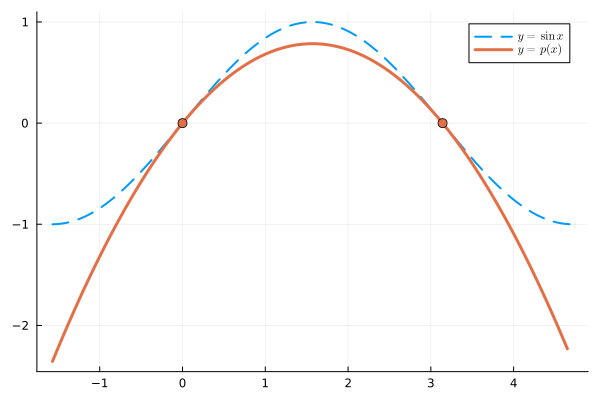

In [3]:
p = Polynomial([0, 1, -1/π])

plot(sin, -π/2, 3π/2; label=L"y = \sin x", lw=2, linestyle=:dash)
plot!(p, -π/2, 3π/2; label=L"y = p(x)", lw=3)
scatter!([0, π], [0, 0]; markersize=5, primary=false)

:::
:::

::: {.callout-tip}
# TO-DO

* Exercises throughout the notes,
* (Sign-up to office hours if you like)

:::

## Extra exercises

::: {#exr-l09-hermite-exist .difficult}

[](../exercises/bank.html#bank-exr-l09-hermite-exist)

In this exercise, we prove @thm-Hermite. As in the notes, let $z_0, \dots, z_k$ be distinct nodes with multiplicities $m_0, \dots, m_k \geq 1$, and let $n + 1 = \sum_{j=0}^k m_j$.

1. Let $r \in \mathcal P_n$ and suppose that $r^{(l)}(z) = 0$ for $l = 0, \dots, m-1$. Show that $r(x) = (x - z)^m s(x)$ for some polynomial $s$.
2. Suppose that $r \in \mathcal P_n$ satisfies $r^{(l)}(z_j) = 0$ for all $l = 0,\dots,m_j - 1$ and $j = 0,\dots,k$. Show that $r = 0$.
3. Deduce that the Hermite interpolation problem has at most one solution in $\mathcal P_n$.
4. Consider the map $L : \mathcal P_n \to \mathbb R^{n+1}$ defined by $L p := \big( p^{(l)}(z_j) \big)_{j = 0,\dots,k, \; l = 0, \dots, m_j - 1}$. Show that $L$ is linear and injective, and conclude that the Hermite interpolation problem has exactly one solution in $\mathcal P_n$.

::: {.exercise-hint style="display: none;"}

**1.** Write $r$ as its Taylor polynomial about $z$ (which is exact because $r$ is a polynomial). 
**2.** Apply 1 at $z_0$ and then show that $s$ still has zeros of order $m_j$ at $z_j$ for $j \geq 1$.
**4.** Use the fact that injective linear maps between vector spaces of the same finite dimension is also surjective.

:::

::: {.exercise-solution style="display: none;"}

1. Since $r \in \mathcal P_n$, Taylor's theorem is exact: 
$$
\begin{align}
    r(x) &= \sum_{l=0}^n \frac{r^{(l)}(z)}{l!} (x - z)^l \nonumber\\
    &= \sum_{l=m}^n \frac{r^{(l)}(z)}{l!} (x - z)^l \nonumber\\
    &= (x-z)^m s(x)
\end{align}
$$
where $s(x) := \sum_{l=m}^n \frac{r^{(l)}(z)}{l!} (x - z)^{l-m}$.

2. By 1, $r(x) = (x - z_0)^{m_0} s_0(x)$. Fix $j \geq 1$ and write $u(x) := (x - z_0)^{m_0}$ (with $u(z_j) \not= 0$). By the Leibniz rule,
$$
\begin{align}
    r^{(l)}(z_j) &= \sum_{i=0}^l \binom{l}{i} u^{(l-i)}(z_j) \, s_0^{(i)}(z_j) 
    \nonumber\\
    &= u(z_j) \, s_0^{(l)}(z_j) + \sum_{i=0}^{l-1} \binom{l}{i} u^{(l-i)}(z_j) \, s_0^{(i)}(z_j).
\end{align}
$$
By induction on $l = 0, \dots, m_j - 1$, we obtain $s_0^{(l)}(z_j) = 0$. Therefore, $s_0$ satisfies the same conditions at $z_1, \dots, z_k$ and, repeating the argument, we have
$$
    r(x) = (x - z_0)^{m_0} (x - z_1)^{m_1} \cdots (x - z_k)^{m_k} s(x)
$$
for some polynomial $s$. If $s \not= 0$, then $r$ has degree at least $\sum_j m_j = n+1$, which contradicts $r \in \mathcal P_n$. Therefore $s = 0$ and $r = 0$.

3. If $p, q \in \mathcal P_n$ both solve the Hermite interpolation problem, then $r := p - q \in \mathcal P_n$ satisfies $r^{(l)}(z_j) = f^{(l)}(z_j) - f^{(l)}(z_j) = 0$ for all $j$ and $l = 0, \dots, m_j-1$. By 2, $r = 0$ and so $p = q$.

4. Differentiation and evaluation are linear and so $L$ is linear. If $L p = 0$, then $p = 0$ by 2, and so $L$ is injective. Since $\dim \mathcal P_n = n + 1 = \dim \mathbb R^{n+1}$, the rank-nullity theorem shows that $L$ is also surjective. In particular, there exists $p \in \mathcal P_n$ with $L p = \big( f^{(l)}(z_j) \big)_{j,l}$, which is exactly a solution to the Hermite interpolation problem. By 3, this solution is unique.

:::

:::

::: {#exr-l09-hermite-error .difficult}

[](../exercises/bank.html#bank-exr-l09-hermite-error)

In this exercise, we prove the error estimate for Hermite interpolation (compare with the Lagrange case in Lecture 6). We say that $g$ has a *zero of order $m$* at $z$ if $g(z) = g'(z) = \dots = g^{(m-1)}(z) = 0$.

1. (Rolle's theorem with multiplicities) Suppose that $g \in C^1([a,b])$ has zeros at distinct points $w_1 < \dots < w_r$ in $[a,b]$ of orders $k_1, \dots, k_r$, and let $N := k_1 + \dots + k_r$. Show that $g'$ has zeros in $[w_1, w_r]$ whose orders add up to at least $N - 1$.
2. Let $f \in C^{n+1}([a,b])$, let $X = \{\{x_0, \dots, x_n\}\} \subset [a,b]$ be a multiset, and let $p \in \mathcal P_n$ be the Hermite interpolant of $f$ on $X$. Define the node polynomial $\ell_X(x) := (x - x_0)(x - x_1) \cdots (x - x_n)$ (so repeated nodes give repeated factors). Show that, for every $x \in [a,b]$, there exists $\xi_x \in [\min (\{x\} \cup X), \max (\{x\} \cup X)]$ with
$$
    f(x) - p(x) = \frac{f^{(n+1)}(\xi_x)}{(n+1)!} \ell_X(x).
$$

::: {.exercise-hint style="display: none;"}

1. At each $w_i$ the derivative $g'$ has a zero of order $k_i - 1$, and Rolle's theorem gives one more zero strictly between each pair $w_i < w_{i+1}$. 
2. Copy the proof from Lecture 6: for $x \not\in X$, consider 
$$
    g(t) := f(t) - p(t) - \big[ f(x) - p(x) \big] \frac{\ell_X(t)}{\ell_X(x)}
$$ 
and count its zeros with their orders.

:::

::: {.exercise-solution style="display: none;"}

1. At each $w_i$, $g'$ has a zero of order $k_i - 1$ (because $g', \dots, g^{(k_i-1)}$ vanish at $w_i$). Moreover, for each $i = 1, \dots, r-1$, $g(w_i) = g(w_{i+1}) = 0$ and so, by Rolle's theorem, $g'$ has a zero in $(w_i, w_{i+1})$, which is different from all of the $w_i$. Adding these up, the orders of the zeros of $g'$ in $[w_1, w_r]$ add up to at least
$$
    \sum_{i=1}^r (k_i - 1) + (r - 1) = N - 1.
$$

2. If $x \in X$, then both sides are zero (take any $\xi_x$). Otherwise $\ell_X(x) \not= 0$ and we can define
$$
    g(t) := f(t) - p(t) - \big[ f(x) - p(x) \big] \frac{\ell_X(t)}{\ell_X(x)}.
$$
Then $g \in C^{n+1}$. If $z$ appears $m$ times in $X$, then $f - p$ has a zero of order $m$ at $z$ (by the Hermite conditions) and so does $\ell_X$ (it contains the factor $(t - z)^m$). Therefore $g$ has a zero of order $m$ at $z$. Moreover, $g(x) = 0$. So the orders of the zeros of $g$ add up to (at least) $(n + 1) + 1 = n + 2$. Applying 1 $n+1$ times, $g^{(n+1)}$ has a zero $\xi_x$ in $[\min (\{x\} \cup X), \max (\{x\} \cup X)]$. Since $p \in \mathcal P_n$ and $\ell_X$ is monic of degree $n + 1$, we have $p^{(n+1)} = 0$ and $\ell_X^{(n+1)} = (n+1)!$, and so
$$
    0 = g^{(n+1)}(\xi_x) = f^{(n+1)}(\xi_x) - \big[ f(x) - p(x) \big] \frac{(n+1)!}{\ell_X(x)}.
$$
Rearranging gives the result.

:::

:::

::: {#exr-l09-hermite-cubic name="Cubic Hermite interpolation"}

[](../exercises/bank.html#bank-exr-l09-hermite-cubic)

Let $X = \{\{0, 0, 1, 1\}\}$ and suppose that we know $f(0) = y_0$, $f'(0) = s_0$, $f(1) = y_1$ and $f'(1) = s_1$.

1. Compute the divided difference table and show that the Hermite interpolant of $f$ on $X$ is
$$
\begin{align}
    p(x) &= y_0 + s_0 x + (d - s_0) x^2 + (s_0 + s_1 - 2d) \, x^2 (x - 1)
\end{align}
$$
where $d := y_1 - y_0$.
2. Write down $p$ for $f(x) = e^x$ and compare it with @exr-Hermite-1.
3. Use @exr-l09-hermite-error to show that $\max_{x \in [0,1]} |e^x - p(x)| \leq \frac{e}{384}$.
4. More generally, suppose that $p$ is the Hermite interpolant of $f$ on $\{\{a, a, b, b\}\}$. Show that $\max_{x \in [a,b]} |f(x) - p(x)| \leq \frac{(b-a)^4}{384} \max_{[a,b]} |f^{(4)}|$. What does this tell you about approximating $f$ on $[a,b]$ by a cubic Hermite interpolant on each $n$ subintervals of length $h = \frac{b-a}{n}$?

::: {.exercise-solution style="display: none;"}

1. With $x_0 = x_1 = 0$ and $x_2 = x_3 = 1$, the table is
$$
\begin{array}{c|cccc}
    x_j & f(x_j) & \text{1st} & \text{2nd} & \text{3rd} \\ \hline
    0 & y_0 & & & \\
      & & s_0 & & \\
    0 & y_0 & & d - s_0 & \\
      & & d & & s_0 + s_1 - 2d \\
    1 & y_1 & & s_1 - d & \\
      & & s_1 & & \\
    1 & y_1 & & &
\end{array}
$$
since $f[0,0] = f'(0) = s_0$, $f[0,1] = \frac{y_1 - y_0}{1 - 0} = d$, $f[1,1] = f'(1) = s_1$, $f[0,0,1] = \frac{d - s_0}{1 - 0}$, $f[0,1,1] = \frac{s_1 - d}{1 - 0}$, and $f[0,0,1,1] = (s_1 - d) - (d - s_0)$. By @thm-Newton-form-Hermite with $\pi_1 = x$, $\pi_2 = x^2$ and $\pi_3 = x^2(x-1)$, we get the formula for $p$. (Check: $p(1) = y_0 + s_0 + d - s_0 = y_1$ and $p'(1) = s_0 + 2(d - s_0) + (s_0 + s_1 - 2d) = s_1$.)

2. Here $y_0 = s_0 = 1$, $y_1 = s_1 = e$ and $d = e - 1$, so
$$
    p(x) = 1 + x + (e - 2) x^2 + (3 - e) \, x^2 (x - 1).
$$
The first three terms are exactly the interpolant from @exr-Hermite-1 on $\{\{0, 0, 1\}\}$: adding the condition $p'(1) = f'(1)$ only adds one new term to the Newton form.

3. By @exr-l09-hermite-error, $e^x - p(x) = \frac{e^{\xi_x}}{4!} x^2 (x-1)^2$ for some $\xi_x \in [0,1]$. The function $x(1 - x)$ has maximum $\frac14$ on $[0,1]$ (at $x = \frac12$), and so $|e^x - p(x)| \leq \frac{e}{24} \cdot \frac{1}{16} = \frac{e}{384} \approx 7.1 \times 10^{-3}$. (Numerically, the maximum error is about $4.4 \times 10^{-3}$.)

4. In the same way, $|f(x) - p(x)| \leq \frac{\max |f^{(4)}|}{24} (x - a)^2 (x - b)^2$ and $(x-a)(b-x) \leq \big(\frac{b - a}{2}\big)^2$, which gives the bound $\frac{(b-a)^4}{16 \cdot 24} \max |f^{(4)}|$. On $n$ subintervals of length $h$, the error is at most $\frac{h^4}{384} \max_{[a,b]} |f^{(4)}|$: halving $h$ divides the error bound by $16$. Moreover, neighbouring cubics share their values and slopes at the break points, so the resulting piecewise cubic is continuously differentiable. (This is *piecewise cubic Hermite interpolation*.)

:::

:::

::: {#exr-l09-dd-mean-value .difficult}

[](../exercises/bank.html#bank-exr-l09-dd-mean-value)

1. Let $f \in C^n([a,b])$ and let $X = \{\{x_0, \dots, x_n\}\} \subset [a,b]$ be a multiset. Show that there exists $\xi \in [\min X, \max X]$ with
$$
    f[x_0, \dots, x_n] = \frac{f^{(n)}(\xi)}{n!}.
$$
2. Deduce that $f[x_0, x_0 + h] \to f'(x_0)$ and, more generally, 
$$
    f[x_0, x_0 + h, \dots, x_0 + nh] \to \frac{f^{(n)}(x_0)}{n!}
$$ 
as $h \to 0$. Explain why this makes the first case of @thm-divided-diffs-recursion a natural definition.

::: {.exercise-hint style="display: none;"}

1. Let $p$ be the Hermite interpolant of $f$ on $X$ and apply part 1 of @exr-l09-hermite-error to $g := f - p$. What is $p^{(n)}$?

:::

::: {.exercise-solution style="display: none;"}

1. Let $p \in \mathcal P_n$ be the Hermite interpolant of $f$ on $X$. Then $g := f - p$ has zeros whose orders add up to $n + 1$ (a zero of order $m$ at each node appearing $m$ times). Applying part 1 of @exr-l09-hermite-error $n$ times, $g^{(n)}$ has a zero $\xi \in [\min X, \max X]$. Since $p(x) = f[x_0, \dots, x_n] x^n + q(x)$ with $q \in \mathcal P_{n-1}$, we have $p^{(n)} = n! \, f[x_0,\dots,x_n]$ and so $0 = f^{(n)}(\xi) - n! \, f[x_0, \dots, x_n]$. (If all the nodes are equal, then $\xi = x_0$ and this is the first case of @thm-divided-diffs-recursion.)

2. By 1, $f[x_0, x_0 + h, \dots, x_0 + nh] = \frac{f^{(n)}(\xi_h)}{n!}$ for some $\xi_h$ between $x_0$ and $x_0 + nh$. As $h \to 0$, $\xi_h \to x_0$ and, since $f^{(n)}$ is continuous, $f^{(n)}(\xi_h) \to f^{(n)}(x_0)$. So the divided difference on $n+1$ nearby nodes converges to $\frac{f^{(n)}(x_0)}{n!}$ as the nodes merge. Defining $f[x_0, \dots, x_0] := \frac{f^{(n)}(x_0)}{n!}$ makes the divided difference continuous in the nodes, and Hermite interpolation is the limit of Lagrange interpolation as nodes come together.

:::

:::

::: {#exr-l09-hermite-code}

[](../exercises/bank.html#bank-exr-l09-hermite-code)

1. Write a Julia function `hermite_dd(x, df)` which takes a vector of nodes `x` (sorted so that equal nodes are next to each other) and a function `df(l, z)` returning $f^{(l)}(z)$, and returns the Newton coefficients $f[x_0], f[x_0,x_1], \dots, f[x_0,\dots,x_n]$ using the divided difference table.
2. Write a function `newton_eval(c, x, t)` which evaluates $\sum_{k=0}^n c_k \pi_k(t)$ using $O(n)$ operations.
3. Check your code against @exr-Hermite-1, @exr-Hermite-2, and @exr-l09-hermite-cubic, and compute $\max_{t \in [0,1]} |e^t - p(t)|$ for the cubic Hermite interpolant of $e^x$ on $\{\{0,0,1,1\}\}$.

::: {.exercise-hint style="display: none;"}

2. Use nested multiplication (Horner's method): $c_0 + (t - x_0)\big(c_1 + (t - x_1)\big(c_2 + \cdots\big)\big)$.

:::

::: {.exercise-solution style="display: none;"}

In [ ]:
function hermite_dd( x, df )
    n = length(x) - 1
    T = zeros(n+1, n+1)              # T[j+1, k+1] = f[x_j, ..., x_{j+k}]
    for j ∈ 0:n
        T[j+1, 1] = df(0, x[j+1])
    end
    for k ∈ 1:n, j ∈ 0:(n-k)
        if x[j+k+1] == x[j+1]        # all nodes equal
            T[j+1, k+1] = df(k, x[j+1]) / factorial(k)
        else
            T[j+1, k+1] = (T[j+2, k] - T[j+1, k]) / (x[j+k+1] - x[j+1])
        end
    end
    return T[1, :]                   # top diagonal
end

function newton_eval( c, x, t )
    p = c[end]
    for k ∈ (length(c)-1):-1:1
        p = c[k] + (t - x[k]) * p
    end
    return p
end

dsin(l, z) = (sin(z), cos(z), -sin(z), -cos(z))[l % 4 + 1]
dexp(l, z) = exp(z)

X = [0, 0, 1, 1]
c = hermite_dd(X, dexp)
t = range(0, 1, length=10001)
err = maximum( abs.( exp.(t) .- newton_eval.(Ref(c), Ref(X), t) ) )

println("Hermite-1, e^x on {{0,0,1}}:")
println("  computed: ", hermite_dd([0, 0, 1], dexp))
println("  exact:    ", [1, 1, ℯ - 2])
println("Hermite-2, sin x on {{0,0,π,π}}:")
println("  computed: ", hermite_dd([0, 0, π, π], dsin))
println("  exact:    ", [0, 1, -1/π, 0])
println("Cubic Hermite, e^x on {{0,0,1,1}}:")
println("  computed: ", c)
println("  exact:    ", [1, 1, ℯ - 2, 3 - ℯ])
println("max |e^t - p(t)| on [0,1] = ", err, "  (bound e/384 = ", ℯ/384, ")")

Hermite-1, e^x on {{0,0,1}}:
  computed: [1.0, 1.0, 0.7182818284590451]
  exact:    [1.0, 1.0, 0.7182818284590451]
Hermite-2, sin x on {{0,0,π,π}}:
  computed: [0.0, 1.0, -0.3183098861837907, 0.0]
  exact:    [0.0, 1.0, -0.3183098861837907, 0.0]
Cubic Hermite, e^x on {{0,0,1,1}}:
  computed: [1.0, 1.0, 0.7182818284590451, 0.2817181715409549]
  exact:    [1.0, 1.0, 0.7182818284590451, 0.2817181715409549]
max |e^t - p(t)| on [0,1] = 0.004371001067176472  (bound e/384 = 0.007078858928278763)



The table needs $O(n^2)$ operations and `newton_eval` needs $O(n)$ operations per point.

:::

:::